<a href="https://colab.research.google.com/github/MirandaBazalar/Seattle-Gas-Stations/blob/main/Seattle_Gas_Stations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [178]:
#Instalación de librerías
!pip install geopandas osmnx mapclassify

In [179]:
import geopandas as gpd
#Lectura de los datos censales de Seattle
filez ="https://github.com/MirandaBazalar/Seattle-Gas-Stations/raw/refs/heads/main/2020_Census_Tracts_Seattle_8661193084158732132%20%281%29.zip"
seattle = gpd.read_file(filez)
seattle.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 177 entries, 0 to 176
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   GEOID20     177 non-null    object  
 1   GROSS_ACRE  177 non-null    float64 
 2   LAND_ACRES  177 non-null    float64 
 3   WATER_ACRE  177 non-null    float64 
 4   NAME        177 non-null    object  
 5   TRACT_NUMB  177 non-null    int64   
 6   BASENAME    177 non-null    object  
 7   UVDA_AREA   177 non-null    object  
 8   CRA_NO      177 non-null    float64 
 9   CRA_GRP     177 non-null    int32   
 10  GEN_ALIAS   177 non-null    object  
 11  DETL_NAMES  177 non-null    object  
 12  C_DISTRICT  177 non-null    int64   
 13  geometry    177 non-null    geometry
dtypes: float64(4), geometry(1), int32(1), int64(2), object(6)
memory usage: 18.8+ KB


In [180]:
seattle
seattle.crs

<Projected CRS: PROJCS["NAD83(HARN) / Washington North (ftUS)",GEO ...>
Name: NAD83(HARN) / Washington North (ftUS)
Axis Info [cartesian]:
- [east]: Easting (US survey foot)
- [north]: Northing (US survey foot)
Area of Use:
- undefined
Coordinate Operation:
- name: unnamed
- method: Lambert Conic Conformal (2SP)
Datum: NAD83 (High Accuracy Reference Network)
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

In [181]:
# Union de los polígonos para obtener el límite de Seattle
seattle_dissolved = seattle[['geometry']].dissolve()
seattle_dissolved

,geometry
0,"MULTIPOLYGON (((1260535.89 188253.83, 1260523...."


In [182]:
#Proyección a un sistema de coordenadas en metros
seattle_dissolved.crs
Seattle_crs = "EPSG:26910"
seattle_dissolved = seattle_dissolved.to_crs(Seattle_crs)
seattle_dissolved.crs

<Projected CRS: EPSG:26910>
Name: NAD83 / UTM zone 10N
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: North America - between 126°W and 120°W - onshore and offshore. Canada - British Columbia; Northwest Territories; Yukon. United States (USA) - California; Oregon; Washington.
- bounds: (-126.0, 30.54, -119.99, 81.8)
Coordinate Operation:
- name: UTM zone 10N
- method: Transverse Mercator
Datum: North American Datum 1983
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

In [183]:
#Obtención de las estaciones de gasolina
import osmnx as ox
stations=ox.features_from_place("Seattle, Washington, USA", tags={'amenity':'fuel'})


In [184]:
stations.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
MultiIndex: 128 entries, ('node', np.int64(457773031)) to ('way', np.int64(1460417274))
Data columns (total 73 columns):
 #   Column                     Non-Null Count  Dtype   
---  ------                     --------------  -----   
 0   geometry                   128 non-null    geometry
 1   amenity                    128 non-null    object  
 2   brand                      111 non-null    object  
 3   brand:wikidata             109 non-null    object  
 4   name                       122 non-null    object  
 5   addr:city                  47 non-null     object  
 6   addr:housenumber           51 non-null     object  
 7   addr:postcode              46 non-null     object  
 8   addr:street                51 non-null     object  
 9   check_date                 65 non-null     object  
 10  compressed_air             60 non-null     object  
 11  opening_hours              51 non-null     object  
 12  website                    49 

In [185]:
stations.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [186]:
stations

geometry amenity  \
element id                                                                      
node    457773031                         POINT (-122.39997 47.63939)    fuel   
        631386821                          POINT (-122.3203 47.62518)    fuel   
        771801423                         POINT (-122.35525 47.73205)    fuel   
        1197964284                        POINT (-122.32958 47.58001)    fuel   
        1489962206                        POINT (-122.32805 47.66483)    fuel   
...                                                               ...     ...   
way     684913608   POLYGON ((-122.37612 47.5448, -122.37623 47.54...    fuel   
        727276570   POLYGON ((-122.33603 47.53219, -122.33603 47.5...    fuel   
        940949039   POLYGON ((-122.26383 47.68144, -122.26394 47.6...    fuel   
        1106778201  POLYGON ((-122.30916 47.57672, -122.30956 47.5...    fuel   
        1460417274  POLYGON ((-122.29762 47.5779, -122.29746 47.57...    fuel   

                       brand brand:wikidata                          name  \
element id                                                                  
node    457773031    Chevron        Q319642              Magnolia Chevron   
        631386821         76       Q1658320                            76   
        771801423    Chevron        Q319642                       Chevron   
        1197964284     Shell     Q110716465                         Shell   
        1489962206  7-Eleven        Q259340                      7-Eleven   
...                      ...            ...                           ...   
way     684913608        NaN            NaN  Gasco & South Seattle Market   
        727276570      Shell     Q110716465                       Shree's   
        940949039   7-Eleven        Q259340                      7-Eleven   
        1106778201  Sinclair            NaN                           NaN   
        1460417274      Arco        Q304769                          Arco   

                   addr:city addr:housenumber addr:postcode  \
element id                                                    
node    457773031        NaN              NaN           NaN   
        631386821    Seattle              915         98102   
        771801423        NaN              NaN           NaN   
        1197964284       NaN              NaN           NaN   
        1489962206       NaN              NaN           NaN   
...                      ...              ...           ...   
way     684913608        NaN              NaN           NaN   
        727276570    Seattle              140         98106   
        940949039        NaN              NaN           NaN   
        1106778201       NaN              NaN           NaN   
        1460417274       NaN              NaN           NaN   

                                addr:street  check_date  ... start_date  \
element id                                               ...              
node    457773031                       NaN         NaN  ...        NaN   
        631386821           East Roy Street  2024-08-13  ...        NaN   
        771801423                       NaN         NaN  ...        NaN   
        1197964284                      NaN         NaN  ...        NaN   
        1489962206                      NaN  2026-02-18  ...        NaN   
...                                     ...         ...  ...        ...   
way     684913608                       NaN         NaN  ...        NaN   
        727276570   Southwest Kenyon Street         NaN  ...        NaN   
        940949039                       NaN         NaN  ...        NaN   
        1106778201                      NaN         NaN  ...        NaN   
        1460417274                      NaN         NaN  ...        NaN   

                   fuel:e85 maxheight contact:facebook contact:instagram  \
element id                                                                 
node    457773031       NaN       NaN              NaN   

In [187]:
stations.index

MultiIndex([('node',  457773031),
            ('node',  631386821),
            ('node',  771801423),
            ('node', 1197964284),
            ('node', 1489962206),
            ('node', 2266423106),
            ('node', 2702032640),
            ('node', 2702054487),
            ('node', 2995124967),
            ('node', 5283345524),
            ...
            ( 'way',  600101678),
            ( 'way',  600101691),
            ( 'way',  600101760),
            ( 'way',  603557992),
            ( 'way',  616232144),
            ( 'way',  684913608),
            ( 'way',  727276570),
            ( 'way',  940949039),
            ( 'way', 1106778201),
            ( 'way', 1460417274)],
           names=['element', 'id'], length=128)

In [188]:
stations.reset_index(drop=False, inplace=True)
stations.head()

,element,id,geometry,amenity,brand,brand:wikidata,name,addr:city,addr:housenumber,addr:postcode,...,start_date,fuel:e85,maxheight,contact:facebook,contact:instagram,contact:phone,contact:twitter,contact:youtube,landuse,mapwithai:source
0,node,457773031,POINT (-122.39997 47.63939),fuel,Chevron,Q319642,Magnolia Chevron,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,node,631386821,POINT (-122.3203 47.62518),fuel,76,Q1658320,76,Seattle,915,98102,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,node,771801423,POINT (-122.35525 47.73205),fuel,Chevron,Q319642,Chevron,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,node,1197964284,POINT (-122.32958 47.58001),fuel,Shell,Q110716465,Shell,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,node,1489962206,POINT (-122.32805 47.66483),fuel,7-Eleven,Q259340,7-Eleven,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [189]:
#Selección de las columnas necesarias
colsToKeep = ['element','name','geometry']
fuelSeattle = stations[colsToKeep].copy()

In [190]:
fuelSeattle = fuelSeattle.to_crs(Seattle_crs)

In [191]:
fuelSeattle.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 128 entries, 0 to 127
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   element   128 non-null    object  
 1   name      122 non-null    object  
 2   geometry  128 non-null    geometry
dtypes: geometry(1), object(2)
memory usage: 3.1+ KB


In [192]:
#Reemplazar los nombres faltantes
fuelSeattle.fillna({'name':'Unknown'},inplace=True)

In [193]:
fuelSeattle.index.astype(str)+"_"+fuelSeattle.name

,0
0,0_Magnolia Chevron
1,1_76
2,2_Chevron
3,3_Shell
4,4_7-Eleven
...,...
123,123_Gasco & South Seattle Market
124,124_Shree's
125,125_7-Eleven
126,126_Unknown


In [194]:
#Crear identificadores únicos para las gasolineras
fuelSeattle['newname']=fuelSeattle.index.astype(str) + "_" + fuelSeattle.name
fuelSeattle.set_index('newname',inplace=True)
fuelSeattle.drop(columns=['name'],inplace=True)
fuelSeattle.head()

,element,geometry
newname,,
0_Magnolia Chevron,node,POINT (545070.577 5276395.041)
1_76,node,POINT (551068.412 5274865.552)
2_Chevron,node,POINT (548343.649 5286720.849)
3_Shell,node,POINT (550414.847 5269839.108)
4_7-Eleven,node,POINT (550448.153 5279266.856)


In [195]:
#Comparar los tipos de elementos y geometrías
import pandas as pd
pd.crosstab(fuelSeattle.element,fuelSeattle.geometry.geom_type, margins=True)

col_0,Point,Polygon,All
element,,,
node,17,0,17
way,0,111,111
All,17,111,128


In [196]:
stations[stations.element == 'relation']

,element,id,geometry,amenity,brand,brand:wikidata,name,addr:city,addr:housenumber,addr:postcode,...,start_date,fuel:e85,maxheight,contact:facebook,contact:instagram,contact:phone,contact:twitter,contact:youtube,landuse,mapwithai:source


In [197]:
#Obtener los centros educativos de Seattle
schools=ox.features_from_place("Seattle, Washington, USA",
                               tags={'amenity':'school'})
schools.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
MultiIndex: 217 entries, ('node', np.int64(356540545)) to ('way', np.int64(1547977369))
Data columns (total 74 columns):
 #   Column                   Non-Null Count  Dtype   
---  ------                   --------------  -----   
 0   geometry                 217 non-null    geometry
 1   amenity                  217 non-null    object  
 2   check_date               26 non-null     object  
 3   ele                      140 non-null    object  
 4   gnis:feature_id          146 non-null    object  
 5   name                     215 non-null    object  
 6   addr:city                158 non-null    object  
 7   addr:housenumber         166 non-null    object  
 8   addr:postcode            157 non-null    object  
 9   addr:street              166 non-null    object  
 10  opening_hours            36 non-null     object  
 11  website                  111 non-null    object  
 12  religion                 25 non-null     object  
 13  nam

In [198]:
schools.reset_index(inplace=True)
#Seleccionar las columnas necesarias
schoolSeattle = schools[['element', 'name','geometry']].copy()
#Reemplazar los nombres faltantes
schoolSeattle.fillna({'name':'Unknown'},inplace=True)

schoolSeattle['newname']=schoolSeattle.index.astype(str) + "_" + schoolSeattle.name
schoolSeattle.set_index('newname', inplace=True)
schoolSeattle.drop(columns=['name'],inplace=True)
schoolSeattle = schoolSeattle.to_crs(Seattle_crs)
schoolSeattle.head()

,element,geometry
newname,,
0_Mapleleaf School,node,POINT (552925.436 5283350.335)
1_Hazel Wolf K-8,node,POINT (550876.028 5280652.219)
2_Epic Life Academy,node,POINT (549394.116 5283758.769)
3_Christ the King Elementary School,node,POINT (548515.145 5284662.849)
4_Assumption Saint Bridget School,node,POINT (553072.046 5280365.741)


In [199]:
pd.crosstab(schoolSeattle.element,schoolSeattle.geometry.geom_type, margins=True)

col_0,MultiPolygon,Point,Polygon,All
element,,,,
node,0,54,0,54
relation,4,0,2,6
way,0,0,157,157
All,4,54,159,217


In [200]:
schools[(schools.element=='relation') & (schools.geometry.geom_type=='MultiPolygon')]

,element,id,geometry,amenity,check_date,ele,gnis:feature_id,name,addr:city,addr:housenumber,...,building:levels,fax,short_name,start_date,addr:housename,nursery,preschool,school:language,layer,type
54,relation,537423,"MULTIPOLYGON (((-122.2931 47.57649, -122.29298...",school,NaN,28,1505026,Franklin High School,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,multipolygon
56,relation,4764405,"MULTIPOLYGON (((-122.31777 47.64223, -122.3176...",school,NaN,62,1515690,Seattle Preparatory School,Seattle,2400,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,multipolygon
57,relation,7616973,"MULTIPOLYGON (((-122.33765 47.69496, -122.3376...",school,NaN,NaN,NaN,Cascadia Elementary School,Seattle,1700,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,multipolygon
59,relation,18609000,"MULTIPOLYGON (((-122.26364 47.67391, -122.2636...",school,NaN,NaN,NaN,Sand Point Elementary School,Seattle,6208,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,multipolygon


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

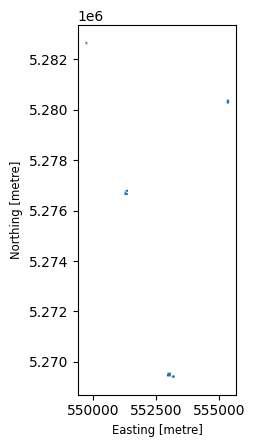

In [201]:
schoolSeattle[(schoolSeattle.element=='relation') & (schoolSeattle.geometry.geom_type=='MultiPolygon')].plot()

In [202]:
#Visualizar las escuelas y gasolineras en Seattle
base = seattle_dissolved.explore(tiles='cartodbpositron', color='lightblue')
schoolSeattle.explore(m=base, color='k')
fuelSeattle.explore(m=base, color='red')


/usr/local/lib/python3.13/dist-packages/geopandas/explore.py:383: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(scale_factor="{r}")


## Explorar proximidad:

In [203]:
#Distancias entre estaciones de gasolina
D_Matrix_fuel_fuel=fuelSeattle.geometry.apply\
  (lambda station:fuelSeattle.geometry.distance(station))
D_Matrix_fuel_fuel

newname,0_Magnolia Chevron,1_76,2_Chevron,3_Shell,4_7-Eleven,5_7-Eleven,6_Morrison's North Star Marine,7_Shilshole Fuel Dock,8_Dr. Dan's Biodiesel,9_76,...,118_Chevron,119_76,120_Chevron,121_Safeway Fuel Station,122_Shell,123_Gasco & South Seattle Market,124_Shree's,125_7-Eleven,126_Unknown,127_Arco
newname,,,,,,,,,,,,,,,,,,,,,
0_Magnolia Chevron,0.000000,6189.778099,10832.142978,8458.219249,6096.362935,3911.871820,4154.629544,4607.185893,3684.919842,6799.259673,...,11032.720301,8059.083730,8471.490011,11342.071122,8388.488702,10650.766388,12839.472695,11229.479609,9704.676294,10259.885224
1_76,6189.778099,0.000000,12164.390410,5068.756372,4444.794018,7396.837510,2913.822486,9025.058016,5776.876534,2146.281615,...,10502.171854,9283.591945,5828.349523,6582.987118,3490.937461,9859.853435,10391.001557,7544.714281,5423.572544,5486.468930
2_Chevron,10832.142978,12164.390410,0.000000,17008.322965,7745.382606,6939.794167,9680.781667,6982.575734,7498.129000,14199.195661,...,3434.731016,2961.691541,7436.375075,18706.121900,15655.292108,20857.745519,22251.515513,8863.786937,17578.604974,17632.751402
3_Shell,8458.219249,5068.756372,17008.322965,0.000000,9427.806838,11287.548358,7342.660400,12635.016000,9933.327451,2922.512744,...,15557.714940,14059.287367,10879.733945,3206.070889,2163.657924,5243.026228,5325.665547,12298.163104,1528.265114,2402.851126
4_7-Eleven,6096.362935,4444.794018,7745.382606,9427.806838,0.000000,4594.203464,2537.458079,6272.831613,3095.924539,6540.437675,...,6182.494529,4939.340577,2378.849213,10960.740771,7927.629559,13808.912707,14744.043923,5152.034055,9868.081904,9889.821437
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
123_Gasco & South Seattle Market,10650.766388,9859.853435,20857.745519,5243.026228,13808.912707,14330.734414,11384.887382,15256.296547,13384.622284,7840.707251,...,19975.906239,17895.800659,15622.732075,7048.807065,7406.644471,0.000000,3320.967459,17353.381510,6121.528764,6950.536820
124_Shree's,12839.472695,10391.001557,22251.515513,5325.665547,14744.043923,16185.514303,12571.965336,17343.197545,14990.551645,8245.361423,...,20883.253836,19286.809328,16183.027772,5393.694936,7165.874001,3320.967459,0.000000,17427.534449,5304.377123,5824.618469
125_7-Eleven,11229.479609,7544.714281,8863.786937,12298.163104,5152.034055,9340.534273,7314.479491,10839.148958,8108.038042,9514.437711,...,5617.194131,7342.966295,2828.590101,12564.668105,10253.850567,17353.381510,17427.534449,0.000000,12100.385190,11735.314154


In [204]:
D_Matrix_fuel_fuel.replace(0,None,inplace=True)
D_Matrix_fuel_fuel.min(axis=1).sort_values().head(10)

,0
newname,
104_ARCO,3.577986
103_ARCO,3.577986
89_76,4.467367
88_76,4.467367
30_Chevron,9.231022
11_Chevron,9.231022
91_Shell,10.521046
90_Shell,10.521046
60_Pacific Pride,12.428133


In [205]:
#Distancias entre estaciones de gasolinas y escuelas
D_Matrix_fuel_school=fuelSeattle.geometry.apply\
(lambda station: schoolSeattle.geometry.distance(station))

D_Matrix_fuel_school

newname,0_Mapleleaf School,1_Hazel Wolf K-8,2_Epic Life Academy,3_Christ the King Elementary School,4_Assumption Saint Bridget School,5_Saint Edward Parish School,6_Learning Way School,7_Concordia Lutheran School,8_Northwest Montessori School,9_Northwest Childrens Academy,...,207_Rainier Valley Leadership Academy,208_Eckstein Middle School,209_La Escuelita Bilingual School,210_Impact | Salish Sea Elementary,211_Little Laurels,212_Cascade Parent Partnership Program,213_Roxhill Elementary School,214_Downtown School,215_Seattle Waldorf School - Main Campus,216_Mercer International Middle School
newname,,,,,,,,,,,,,,,,,,,,,
0_Magnolia Chevron,10491.659688,7199.084975,8539.173303,8956.657111,8932.523151,13341.958719,13507.709663,9506.260725,4487.653030,5324.737909,...,13761.296382,9053.687052,7195.602311,14410.390399,12230.115714,3124.787461,13580.295215,4054.694024,10282.565861,10565.424327
1_76,8685.624613,5789.863861,9049.451299,10124.534305,5853.770242,8808.620825,11975.722628,6599.617370,5074.222149,880.126226,...,9194.797832,6402.592462,6089.745057,10238.137431,10878.978200,3673.708903,12398.535914,2554.619356,8612.096410,6727.699624
2_Chevron,5687.981663,6575.805111,3142.833012,2065.133147,7921.183151,20929.652730,23474.696332,7563.706626,7465.701803,11654.725826,...,21301.486962,7045.990100,6198.145060,22392.998311,4983.299678,9477.043229,23725.977819,12427.156563,5446.866035,18854.337587
3_Shell,13742.500324,10822.941478,13957.036131,14944.971496,10856.827909,4930.152593,6965.257592,11596.129786,9605.655198,5388.607746,...,5347.980500,11437.825204,11106.714608,5956.588399,15939.807496,7649.546886,7450.088356,4780.314108,13675.664902,2107.909975
4_7-Eleven,4776.163021,1449.933898,4613.922112,5731.776499,2844.708492,13184.453100,16181.746778,3413.989799,1921.307178,4045.349103,...,13557.409322,2975.949318,1688.226327,14650.612357,6843.922072,3022.474841,16531.995201,5311.494858,4626.744314,11169.644124
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
123_Gasco & South Seattle Market,18437.654830,15257.637660,18016.092365,18818.447390,15701.177153,7223.804112,2917.573907,16447.522259,13440.851728,9890.137026,...,7489.956010,16219.730566,15482.629187,7043.580298,20596.596876,11308.744575,2917.011727,8493.599402,18333.769195,5192.808772
124_Shree's,19046.714482,16146.376840,19238.321146,20186.490665,16131.338043,4633.509651,2212.511637,16863.752907,14799.205507,10699.306284,...,4762.577365,16729.265591,16426.505984,3973.425033,21246.496324,12755.913237,2957.170911,9823.178035,18986.753055,3812.301432
125_7-Eleven,3191.366019,4396.077208,6402.128582,7587.141782,2308.936140,14581.418422,19250.984757,1890.496999,6978.426106,7738.111508,...,14859.036606,2191.162884,4562.774267,16156.189878,4800.640849,8052.316222,19748.085148,9560.847169,3273.765496,13416.903822


In [206]:
D_Matrix_fuel_school.min(axis=1).sort_values().head(10)

,0
newname,
102_Shell,0.824760
38_Shell,23.258460
69_Shell,36.646314
1_76,75.072216
111_Space Age,91.233431
74_Shell,94.493039
109_Shell,97.053490
96_Chevron,100.324890
36_Chevron,112.051912


In [207]:
#Establecer una distancia mínima de 200 metros
mindDist = 200

In [208]:
schoolSeattle_buffered=schoolSeattle.buffer(mindDist)
schoolSeattle_buffered

,0
newname,
0_Mapleleaf School,"POLYGON ((553125.436 5283350.335, 553124.473 5..."
1_Hazel Wolf K-8,"POLYGON ((551076.028 5280652.219, 551075.065 5..."
2_Epic Life Academy,"POLYGON ((549594.116 5283758.769, 549593.153 5..."
3_Christ the King Elementary School,"POLYGON ((548715.145 5284662.849, 548714.182 5..."
4_Assumption Saint Bridget School,"POLYGON ((553272.046 5280365.741, 553271.083 5..."
...,...
212_Cascade Parent Partnership Program,"POLYGON ((548097.853 5277444.55, 548200.996 52..."
213_Roxhill Elementary School,"POLYGON ((547208.545 5263118.173, 547211.211 5..."
214_Downtown School,"POLYGON ((548577.36 5274495.399, 548596.968 52..."


In [209]:
type(schoolSeattle_buffered)

geopandas.geoseries.GeoSeries

In [210]:
secured_schoolSeattle=gpd.GeoDataFrame(geometry=schoolSeattle_buffered)
secured_schoolSeattle

,geometry
newname,
0_Mapleleaf School,"POLYGON ((553125.436 5283350.335, 553124.473 5..."
1_Hazel Wolf K-8,"POLYGON ((551076.028 5280652.219, 551075.065 5..."
2_Epic Life Academy,"POLYGON ((549594.116 5283758.769, 549593.153 5..."
3_Christ the King Elementary School,"POLYGON ((548715.145 5284662.849, 548714.182 5..."
4_Assumption Saint Bridget School,"POLYGON ((553272.046 5280365.741, 553271.083 5..."
...,...
212_Cascade Parent Partnership Program,"POLYGON ((548097.853 5277444.55, 548200.996 52..."
213_Roxhill Elementary School,"POLYGON ((547208.545 5263118.173, 547211.211 5..."
214_Downtown School,"POLYGON ((548577.36 5274495.399, 548596.968 52..."


In [211]:
secured_schoolSeattle.geometry.geom_type.value_counts()

,count
Polygon,217


In [212]:
fuelSeattle.geometry.geom_type.value_counts()

,count
Polygon,111
Point,17


In [213]:
#Convertir las gasolineras representadas por puntos en polígonos
fuelSeattle_allPoly = fuelSeattle.copy()

fuelSeattle_allPoly['geometry'] = [
    station.buffer(10) if station.geom_type == 'Point' else station
    for station in fuelSeattle.geometry
]

In [214]:
fuelSeattle_allPoly.geometry.geom_type.value_counts()

,count
Polygon,128


In [215]:
#Identificar las intersecciones con las áreas de seguridad
fuelSeattle_allPoly.overlay(secured_schoolSeattle,how='intersection',keep_geom_type=False)

,element,geometry
0,node,"POLYGON ((551078.363 5274864.572, 551078.219 5..."
1,node,"POLYGON ((551078.363 5274864.572, 551078.219 5..."
2,node,"POLYGON ((550424.799 5269838.128, 550424.655 5..."
3,node,"POLYGON ((545961.026 5280205.552, 545960.882 5..."
4,node,"POLYGON ((553782.981 5266125.595, 553782.837 5..."
5,node,"POLYGON ((548171.127 5263444.827, 548170.983 5..."
6,way,"POLYGON ((549200.164 5283742.752, 549194.91 52..."
7,way,"POLYGON ((546272.901 5269904.828, 546264.427 5..."
8,way,"POLYGON ((552390.26 5272921.862, 552382.489 52..."
9,way,"POLYGON ((552390.26 5272921.862, 552382.489 52..."


In [216]:
gas_relocate = fuelSeattle_allPoly.sjoin(secured_schoolSeattle,how='inner',predicate='intersects')

In [217]:
#Identificar registros duplicados
is_duplicate = gas_relocate.index.duplicated(keep=False)

gas_relocate[is_duplicate]


,element,geometry,newname_right
newname_left,,,
1_76,node,"POLYGON ((551078.412 5274865.552, 551078.363 5...",41_St. Nicholas School
1_76,node,"POLYGON ((551078.412 5274865.552, 551078.363 5...",152_Lowell Elementary School
25_Arco,way,"POLYGON ((552390.065 5272931.786, 552390.26 52...",76_Garfield High School
25_Arco,way,"POLYGON ((552390.065 5272931.786, 552390.26 52...",187_Nova High School
69_Shell,way,"POLYGON ((551874.231 5273802.685, 551871.234 5...",198_Seattle World School
69_Shell,way,"POLYGON ((551874.231 5273802.685, 551871.234 5...",116_Morningside Academy
69_Shell,way,"POLYGON ((551874.231 5273802.685, 551871.234 5...",51_The Hatch School
72_7-Eleven,way,"POLYGON ((551684.055 5273748.468, 551690.484 5...",198_Seattle World School
72_7-Eleven,way,"POLYGON ((551684.055 5273748.468, 551690.484 5...",116_Morningside Academy


In [218]:
gas_relocate.reset_index(drop=False).\
drop_duplicates(subset='newname_left').\
set_index('newname_left')

,element,geometry,newname_right
newname_left,,,
1_76,node,"POLYGON ((551078.412 5274865.552, 551078.363 5...",41_St. Nicholas School
3_Shell,node,"POLYGON ((550424.847 5269839.108, 550424.799 5...",18_Career Link School
5_7-Eleven,node,"POLYGON ((545961.074 5280206.532, 545961.026 5...",139_Adams Elementary School
13_Chevron,node,"POLYGON ((553783.029 5266126.575, 553782.981 5...",169_Aki Kurose Middle School
14_Gas & Smoke Depot,node,"POLYGON ((548171.175 5263445.807, 548171.127 5...",6_Learning Way School
19_Arco,way,"POLYGON ((549199.723 5283761.099, 549200.164 5...",2_Epic Life Academy
21_Safeway,way,"POLYGON ((546272.699 5269920.842, 546272.901 5...",98_Lafayette Elementary School
25_Arco,way,"POLYGON ((552390.065 5272931.786, 552390.26 52...",76_Garfield High School
34_Chevron,way,"POLYGON ((546913.57 5282556.957, 546902.092 52...",199_Whitman Middle School


In [219]:
gas_relocate= gas_relocate.reset_index(drop=False).drop_duplicates(subset='newname_left').\
              set_index('newname_left')

In [220]:
#Visualizar las gasolieras dentro de las áreas de seguridad
base=secured_schoolSeattle.sjoin(gas_relocate,how='inner',predicate='intersects').explore(color='yellow',tiles='cartodbpositron')
gas_relocate.explore(m=base,color='red')


/usr/local/lib/python3.13/dist-packages/geopandas/explore.py:383: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(scale_factor="{r}")


In [221]:
place="Seattle, Washington, USA"
#Obtener la red vial de Seattle
G= ox.graph_from_place("Seattle, Washington, USA", network_type="drive")
streets=ox.graph_to_gdfs(G, nodes=False, edges=True)
streets.shape

(50301, 15)

In [222]:
streets.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
MultiIndex: 50301 entries, (np.int64(29445663), np.int64(29485641), np.int64(0)) to (np.int64(14237930653), np.int64(53073730), np.int64(0))
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   osmid     50301 non-null  object  
 1   highway   50301 non-null  object  
 2   lanes     38813 non-null  object  
 3   maxspeed  49897 non-null  object  
 4   oneway    50301 non-null  bool    
 5   ref       749 non-null    object  
 6   reversed  50301 non-null  object  
 7   length    50301 non-null  float64 
 8   geometry  50301 non-null  geometry
 9   bridge    484 non-null    object  
 10  name      44926 non-null  object  
 11  tunnel    59 non-null     object  
 12  junction  4742 non-null   object  
 13  access    237 non-null    object  
 14  width     270 non-null    object  
dtypes: bool(1), float64(1), geometry(1), object(12)
memory usage: 7.0+ MB


In [223]:
streets.highway.value_counts().index

Index([                    'residential',                        'tertiary',
                             'secondary',                         'primary',
                          'unclassified',                   'motorway_link',
                                 'trunk',                        'motorway',
                          'primary_link',                  'secondary_link',
                         'tertiary_link',                   'living_street',
         ['residential', 'unclassified'],                      'trunk_link',
                                'busway',         ['tertiary', 'secondary'],
        ['residential', 'living_street'],          ['secondary', 'primary'],
           ['motorway_link', 'motorway'],     ['trunk_link', 'residential'],
            ['tertiary', 'unclassified'],       ['tertiary', 'residential'],
                ['primary', 'secondary'],        ['trunk_link', 'tertiary'],
       ['residential', 'secondary_link'],    ['tertiary', 'secondary_link'],

In [224]:
GAS_STATION_ROAD_TYPES = [
    'motorway', 'primary', 'trunk',
    'motorway_link', 'primary_link', 'trunk_link',
    ['motorway', 'trunk'],
    ['primary', 'motorway_link'],
    ['primary', 'primary_link']
]
suitable_roads = streets[streets.highway.isin(GAS_STATION_ROAD_TYPES)]
suitable_roads.shape

(3709, 15)

In [225]:
#Proyectar las vías al sistema de coordenadas de Seattle
suitable_roads = suitable_roads.to_crs(Seattle_crs)

In [226]:
# Establecer una distancia de separación entre gasolineras
competitionDistance = 100

fuelSeattle_allPoly_buffered = fuelSeattle_allPoly.buffer(competitionDistance)

In [227]:
type(fuelSeattle_allPoly_buffered)

geopandas.geoseries.GeoSeries

In [228]:
secured_fuelSeattle_allPoly = gpd.GeoDataFrame(
    geometry=fuelSeattle_allPoly_buffered
)

In [229]:
# Unir las áreas restringidas de gasolineras y escuelas
secured_areas_dissolved = secured_fuelSeattle_allPoly.overlay(secured_schoolSeattle,how='union',keep_geom_type=False).dissolve()
secured_areas = gpd.GeoDataFrame(geometry=secured_areas_dissolved.geometry)

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

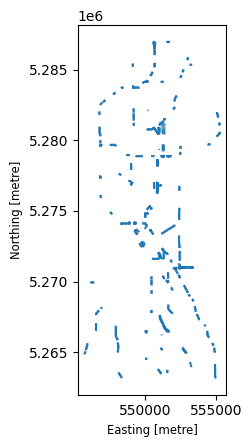

In [230]:
suitable_roads.clip(secured_areas,keep_geom_type=False).plot()

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

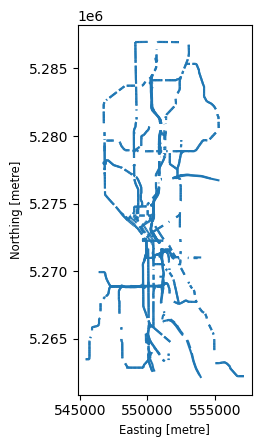

In [231]:
suitable_roads.overlay(secured_areas,keep_geom_type=False,how='difference').plot()

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

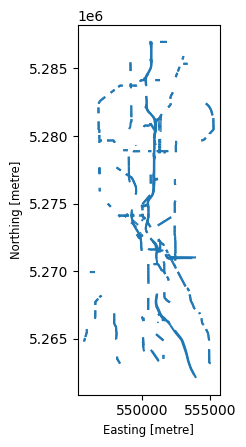

In [232]:
suitable_roads.sjoin(secured_areas, predicate='intersects').plot()

In [233]:
# Excluir las áreas restringidas de las vías seleccionadas
good_routes_forGas_dissolved=suitable_roads.overlay(secured_areas,keep_geom_type=False,how='difference').dissolve()
good_routes_forGas = gpd.GeoDataFrame(geometry=good_routes_forGas_dissolved.geometry)
good_routes_forGas

,geometry
0,"MULTILINESTRING ((551005.064 5276789.854, 5510..."


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

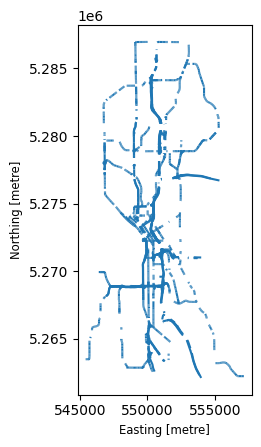

In [234]:
good_routes_forGas.plot()

In [235]:
# Generar nuevas ubicaciones en las vías disponibles
potential_Locations = good_routes_forGas.copy()

newPOLYGONS = []
pointsComputed = 1
attempts = 1

while pointsComputed <= len(gas_relocate):
    candidatePoint = potential_Locations.sample_points(2).apply(
    lambda geom: geom.geoms[0]
)
    candidateStation = gpd.GeoDataFrame(geometry=candidatePoint.buffer(100))

    if candidateStation.overlay(secured_areas, how='intersection', keep_geom_type=False).empty:
        newPOLYGONS.append(candidateStation)
        pointsComputed += 1
        potential_Locations = potential_Locations.overlay(
            candidateStation, how='difference', keep_geom_type=False)

    if attempts > len(gas_relocate) * 10:
        break

    attempts += 1

# some info
attempts, len(newPOLYGONS)


(31, 26)

In [236]:
newPOLYGONS

[                                            geometry
 0  POLYGON ((550566.154 5274614.428, 550565.673 5...,
                                             geometry
 0  POLYGON ((551080.079 5271193.05, 551079.597 52...,
                                             geometry
 0  POLYGON ((549227.873 5280781.913, 549227.391 5...,
                                             geometry
 0  POLYGON ((545811.409 5264445.799, 545810.927 5...,
                                             geometry
 0  POLYGON ((550952.09 5268860.325, 550951.609 52...,
                                             geometry
 0  POLYGON ((550444.91 5282255.591, 550444.428 52...,
                                             geometry
 0  POLYGON ((550631.987 5272253.049, 550631.506 5...,
                                             geometry
 0  POLYGON ((552778.91 5277064.003, 552778.428 52...,
                                             geometry
 0  POLYGON ((551217.566 5270286.87, 551217.085 52...,
                   

In [237]:
pd.concat(newPOLYGONS)

,geometry
0,"POLYGON ((550566.154 5274614.428, 550565.673 5..."
0,"POLYGON ((551080.079 5271193.05, 551079.597 52..."
0,"POLYGON ((549227.873 5280781.913, 549227.391 5..."
0,"POLYGON ((545811.409 5264445.799, 545810.927 5..."
0,"POLYGON ((550952.09 5268860.325, 550951.609 52..."
0,"POLYGON ((550444.91 5282255.591, 550444.428 52..."
0,"POLYGON ((550631.987 5272253.049, 550631.506 5..."
0,"POLYGON ((552778.91 5277064.003, 552778.428 52..."
0,"POLYGON ((551217.566 5270286.87, 551217.085 52..."
0,"POLYGON ((551204.542 5268306.033, 551204.06 52..."


In [238]:
# Unir los polígonos de las nuevas ubicaciones
GoodLocationsGas_buffered_gdf = pd.concat(newPOLYGONS)

# Obtener los centroides de los polígonos
GoodLocationsGas_gdf = gpd.GeoDataFrame(
    geometry=GoodLocationsGas_buffered_gdf.centroid
)

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

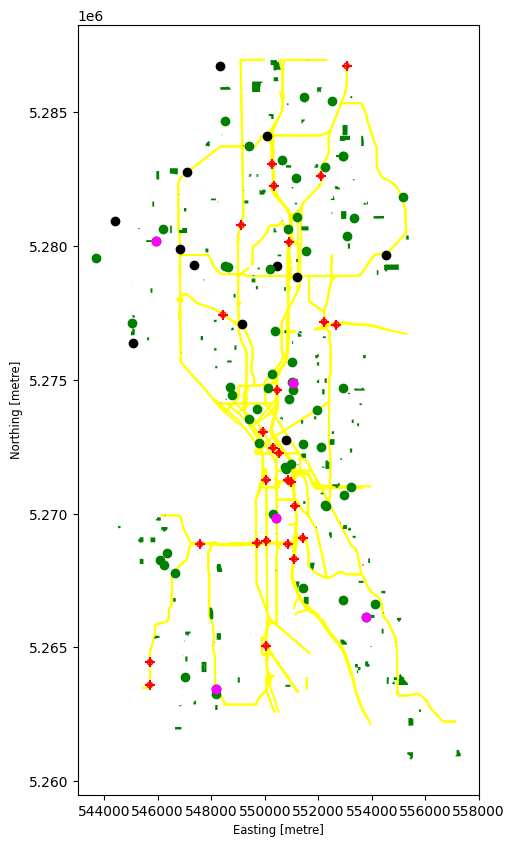

In [239]:
# Visualizar las vías y las ubicaciones propuestas
# Carreteras adecuadas
base = suitable_roads.plot(color='yellow', figsize=(10, 10),zorder=1)

# Zonas de las ubicaciones propuestas
GoodLocationsGas_buffered_gdf.plot(ax=base, edgecolor='red', marker="+", facecolor='none',zorder=2)

# Puntos de las ubicaciones propuestas
GoodLocationsGas_gdf.plot(ax=base, color='red', marker="+", markersize=50,zorder=3)

# Gasolineras existentes
fuelSeattle.plot(ax=base,color='k',zorder=4)

# Centros educativos
schoolSeattle.plot(ax=base,color='green',zorder=5)

# Gasolineras que necesitan reubicarse
fuelSeattle.clip(gas_relocate).plot(ax=base,color='magenta',zorder=6)


In [240]:
# Obtener las direcciones de las ubicaciones propuestas
from geopy.geocoders import Nominatim
import time


geolocator = Nominatim(user_agent="seattle_gas_stations")

def get_address(point):
    lon = point.x
    lat = point.y
    location = geolocator.reverse((lat, lon), exactly_one=True, timeout=10)
    time.sleep(1)

    if location:
        return location.address
    else:
        return None # not found


In [241]:
# Convertir las coordenadas para consultar las direcciones
GoodLocationsGas_4326 = GoodLocationsGas_gdf.to_crs('EPSG:4326')
GoodLocationsGas_gdf['address'] = GoodLocationsGas_4326.geometry.apply(get_address)

In [242]:
GoodLocationsGas_gdf

,geometry,address
0,POINT (550466.154 5274614.428),"I 5, Capitol Hill, Seattle, King County, Washi..."
0,POINT (550980.079 5271193.05),"Charles Street Employee Parking, Airport Way S..."
0,POINT (549127.873 5280781.913),"6865, Aurora Avenue North, Phinney Ridge, Seat..."
0,POINT (545711.409 5264445.799),"7920, Fauntleroy Way Southwest, Seattle, King ..."
0,POINT (550852.09 5268860.325),"West Seattle Bridge, South Seattle, Seattle, K..."
0,POINT (550344.91 5282255.591),"I 5, Green Lake, Seattle, King County, Washing..."
0,POINT (550531.987 5272253.049),"Yesler Way & 5th Avenue, Yesler Way, Japantown..."
0,POINT (552678.91 5277064.003),"Evergreen Point Floating Bridge, Edgewater Par..."
0,POINT (551117.566 5270286.87),"I 5, Beacon Hill, Seattle, King County, Washin..."
0,POINT (551104.542 5268306.033),"I 5, South Seattle, Seattle, King County, Wash..."
